# Question 02


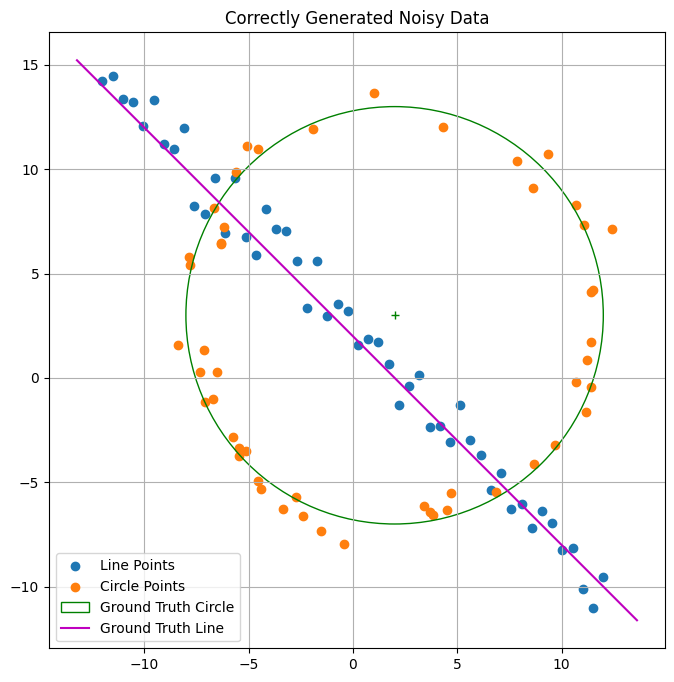

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy import linalg

# Use a seed for reproducible results
np.random.seed(0)

# --- Parameters ---
N = 100
half_n = N // 2

# --- Ground Truth Circle ---
r_gt = 10
x0_gt, y0_gt = 2, 3 # Center
s_circ = r_gt / 16.0
t = np.random.uniform(0, 2*np.pi, half_n)
n_circ = s_circ * np.random.randn(half_n)
x_circ = x0_gt + (r_gt + n_circ) * np.cos(t)
y_circ = y0_gt + (r_gt + n_circ) * np.sin(t)
X_circ = np.hstack((x_circ.reshape(half_n, 1), y_circ.reshape(half_n, 1)))

# --- Ground Truth Line (Corrected Generation) ---
s_line = 1.0
m_gt, b_gt = -1, 2
# Create clean x-coordinates on the line
x_line = np.linspace(-12, 12, half_n)
# Calculate the corresponding y-coordinates and add noise ONLY to y
y_line = m_gt*x_line + b_gt + s_line * np.random.randn(half_n)
X_line = np.hstack((x_line.reshape(half_n, 1), y_line.reshape(half_n, 1)))

# --- Combine all points ---
X = np.vstack((X_circ, X_line))

# --- Plot the newly generated data ---
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:, 0], X_line[:, 1], label='Line Points')
ax.scatter(X_circ[:, 0], X_circ[:, 1], label='Circle Points')

# Plot ground truth circle
circle_gt = plt.Circle((x0_gt, y0_gt), r_gt, color='g', fill=False, label='Ground Truth Circle')
ax.add_patch(circle_gt)
ax.plot(x0_gt, y0_gt, '+', color='g')

# Plot ground truth line
x_range = np.array(ax.get_xlim())
y_range = m_gt * x_range + b_gt
plt.plot(x_range, y_range, color='m', label='Ground Truth Line')

ax.set_aspect('equal', adjustable='box')
plt.title('Correctly Generated Noisy Data')
plt.legend()
plt.grid(True)
plt.show()

### Fitting Functions

In [3]:
# =======================================================
# LINE FITTING FUNCTIONS
# =======================================================

def fit_line_tls(points):
    """
    Fits a line to a set of 2D points using Total Least Squares (TLS).
    The line is represented as ax + by + d = 0, where [a, b] is a unit normal.
    This method is robust and handles both the 2-point sample case and the
    N-point refitting case.
    """
    # For a 2-point sample, the calculation is exact and can be done geometrically
    if len(points) == 2:
        p1, p2 = points[0], points[1]
        a = p1[1] - p2[1]
        b = p2[0] - p1[0]
        # Normalize the normal vector [a, b]
        norm = np.sqrt(a**2 + b**2)
        if norm == 0: return 0, 0, 0 # Should not happen with distinct points
        a /= norm
        b /= norm
        # The distance 'd' is found by ensuring the line passes through p1
        d = -(a * p1[0] + b * p1[1])
        return a, b, d

    # For > 2 points, use Singular Value Decomposition (SVD) for a true TLS fit
    centroid = np.mean(points, axis=0)
    centered_points = points - centroid
    U, S, Vt = np.linalg.svd(centered_points)
    a, b = Vt[-1] # The normal vector is the last row of Vt
    d = -(a * centroid[0] + b * centroid[1])
    return a, b, d

def get_line_distances(points, line_params):
    """Calculates the perpendicular distance from each point to the line ax+by+d=0."""
    a, b, d = line_params
    # Since [a, b] is a unit vector, the distance is simply |ax + by + d|
    return np.abs(a * points[:, 0] + b * points[:, 1] + d)

# =======================================================
# CIRCLE FITTING FUNCTIONS
# =======================================================

def fit_circle_algebraic(points):
    """
    Fits a circle to exactly 3 points using an algebraic method.
    Returns (xc, yc, r) or None if the points are collinear.
    """
    x1, y1 = points[0]; x2, y2 = points[1]; x3, y3 = points[2]

    # Check for collinearity (if the area of the triangle is near zero)
    if abs((y2 - y1) * (x3 - x2) - (y3 - y2) * (x2 - x1)) < 1e-9:
        return None

    # Solve the system of linear equations for the circle center (xc, yc)
    A = np.array([[2*(x2-x1), 2*(y2-y1)], [2*(x3-x2), 2*(y3-y2)]])
    B = np.array([x2**2 - x1**2 + y2**2 - y1**2, x3**2 - x2**2 + y3**2 - y2**2])

    try:
        xc, yc = np.linalg.solve(A, B)
        r = np.sqrt((x1 - xc)**2 + (y1 - yc)**2)
        return xc, yc, r
    except np.linalg.LinAlgError:
        return None

def refit_circle_optimized(points):
    """
    Refits a circle to N > 3 points by minimizing the sum of squared radial errors.
    This uses scipy.optimize.minimize for a robust geometric fit.
    """
    # The function to minimize: sum of squared differences between
    # point-to-center distances and the radius.
    def cost_function(params, points):
        xc, yc, r = params
        distances_to_center = np.sqrt((points[:, 0] - xc)**2 + (points[:, 1] - yc)**2)
        return np.sum((distances_to_center - r)**2)

    # A good initial guess helps the optimizer converge faster and more reliably.
    initial_center = np.mean(points, axis=0)
    initial_radius = np.mean(np.sqrt(np.sum((points - initial_center)**2, axis=1)))
    initial_guess = [initial_center[0], initial_center[1], initial_radius]

    result = minimize(cost_function, initial_guess, args=(points,))
    xc_opt, yc_opt, r_opt = result.x
    return xc_opt, yc_opt, r_opt

def get_circle_distances(points, circle_params):
    """Calculates the radial error (distance) from each point to the circle's circumference."""
    xc, yc, r = circle_params
    distances_to_center = np.sqrt((points[:, 0] - xc)**2 + (points[:, 1] - yc)**2)
    return np.abs(distances_to_center - r)

### (a) RANSAC for Line Fitting

In [4]:
# --- RANSAC Parameters for Line Fitting ---
n_iterations_line = 1000
# The distance threshold should be related to the noise level (s_line = 1.0)
threshold_line = 1.5

# --- RANSAC Loop ---
best_line_model_from_sample = None
best_line_inliers_idx = []
best_line_sample = None
max_inliers_count = 0

print("Running RANSAC for Line Fitting...")
for i in range(n_iterations_line):
    # 1. Randomly sample 2 points from the entire dataset X
    sample_indices = np.random.choice(len(X), 2, replace=False)
    sample_points = X[sample_indices]

    # 2. Fit a line model to this small sample
    current_model = fit_line_tls(sample_points)
    if current_model is None: continue

    # 3. Find the consensus set: all points in X that are "close" to this model
    distances = get_line_distances(X, current_model)
    inlier_indices = np.where(distances < threshold_line)[0]

    # 4. If this model has the most inliers so far, save it as the best one
    if len(inlier_indices) > max_inliers_count:
        max_inliers_count = len(inlier_indices)
        best_line_model_from_sample = current_model
        best_line_inliers_idx = inlier_indices
        best_line_sample = sample_points

# 5. After all iterations, take the best set of inliers and refit the line model
#    using ALL of them. This gives a more accurate result.
line_inliers = X[best_line_inliers_idx]
final_line_model = fit_line_tls(line_inliers)

print(f"  RANSAC Line Fitting Complete.")
print(f"   - Found {len(line_inliers)} inliers for the line.")
print(f"   - Final line model (a, b, d): {np.round(final_line_model, 3)}")

Running RANSAC for Line Fitting...
  RANSAC Line Fitting Complete.
   - Found 56 inliers for the line.
   - Final line model (a, b, d): [ 0.718  0.696 -1.522]


### (b) RANSAC for Circle Fitting

In [5]:
# --- Create the remnant point set by removing the line inliers ---
all_indices = np.arange(len(X))
remnant_indices = np.setdiff1d(all_indices, best_line_inliers_idx)
X_remnant = X[remnant_indices]

# --- RANSAC Parameters for Circle Fitting ---
n_iterations_circle = 1000
# Threshold based on circle noise s_circ = 10/16 = 0.625
threshold_circle = 1.2

# --- RANSAC Loop ---
best_circle_model_from_sample = None
best_circle_inliers_idx_global = [] # Store indices relative to original X
best_circle_sample = None
max_inliers_count_circ = 0

print("\nRunning RANSAC for Circle Fitting on remnant data...")
for i in range(n_iterations_circle):
    # 1. Randomly sample 3 points from the REMNANT set
    sample_indices_remnant = np.random.choice(len(X_remnant), 3, replace=False)
    sample_points = X_remnant[sample_indices_remnant]

    # 2. Fit a circle to the sample
    current_model = fit_circle_algebraic(sample_points)
    if current_model is None: # Skip if the 3 points were collinear
        continue

    # 3. Find the consensus set within the remnant points
    distances = get_circle_distances(X_remnant, current_model)
    inlier_indices_remnant = np.where(distances < threshold_circle)[0]

    # 4. Check if this is the best model so far
    if len(inlier_indices_remnant) > max_inliers_count_circ:
        max_inliers_count_circ = len(inlier_indices_remnant)
        best_circle_model_from_sample = current_model
        # Map local remnant indices back to the global indices of X for plotting
        best_circle_inliers_idx_global = remnant_indices[inlier_indices_remnant]
        best_circle_sample = sample_points

# 5. Refit the circle model using all inliers from the best set for higher accuracy
circle_inliers = X[best_circle_inliers_idx_global]
final_circle_model = refit_circle_optimized(circle_inliers)

print(f"  RANSAC Circle Fitting Complete.")
print(f"   - Found {len(circle_inliers)} inliers for the circle.")
print(f"   - Final circle model (xc, yc, r): {np.round(final_circle_model, 3)}")


Running RANSAC for Circle Fitting on remnant data...
  RANSAC Circle Fitting Complete.
   - Found 43 inliers for the circle.
   - Final circle model (xc, yc, r): [1.869 3.125 9.93 ]


### (c) Final Visualization

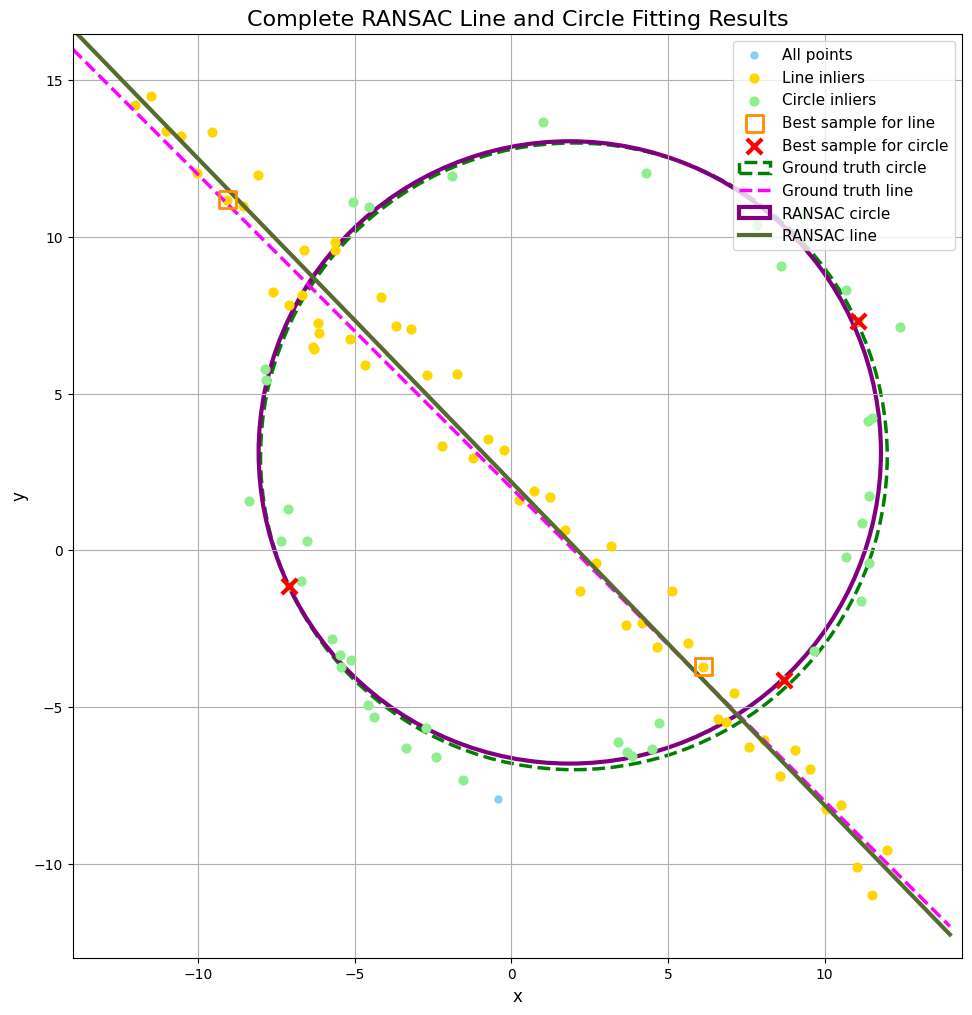

In [7]:
# --- Create the Comprehensive Plot ---
fig, ax = plt.subplots(1, 1, figsize=(12, 12))

# 1. Plot all points (as a background)
ax.scatter(X[:, 0], X[:, 1], c='lightskyblue', label='All points', s=25, zorder=1)

# 2. Plot the identified inliers for each model
ax.scatter(line_inliers[:, 0], line_inliers[:, 1], c='gold', label='Line inliers', s=40, zorder=2)
ax.scatter(circle_inliers[:, 0], circle_inliers[:, 1], c='lightgreen', label='Circle inliers', s=40, zorder=2)

# 3. Highlight the small random samples that led to the best models
ax.scatter(best_line_sample[:, 0], best_line_sample[:, 1], facecolors='none', edgecolors='darkorange', marker='s', s=150, lw=2, label='Best sample for line', zorder=3)
ax.scatter(best_circle_sample[:, 0], best_circle_sample[:, 1], c='red', marker='x', s=120, lw=3, label='Best sample for circle', zorder=3)

# 4. Plot the Ground Truth models for comparison
circle_gt_plot = plt.Circle((x0_gt, y0_gt), r_gt, color='green', fill=False, lw=2.5, ls='--', label='Ground truth circle')
ax.add_patch(circle_gt_plot)
x_vals_plot = np.array([-14, 14])
y_vals_gt = m_gt * x_vals_plot + b_gt
ax.plot(x_vals_plot, y_vals_gt, color='magenta', lw=2.5, ls='--', label='Ground truth line')

# 5. Plot the Final RANSAC Estimated Models (refitted on all inliers)
# RANSAC Circle
ransac_circ_final = plt.Circle((final_circle_model[0], final_circle_model[1]), final_circle_model[2], color='purple', lw=3, fill=False, label='RANSAC circle')
ax.add_patch(ransac_circ_final)
# RANSAC Line
a, b, d = final_line_model
y_vals_ransac = -(a * x_vals_plot + d) / b
ax.plot(x_vals_plot, y_vals_ransac, color='darkolivegreen', lw=3, label='RANSAC line')

# --- Final Plot Settings ---
ax.set_aspect('equal', adjustable='box')
ax.set_xlim(X[:, 0].min() - 2, X[:, 0].max() + 2)
ax.set_ylim(X[:, 1].min() - 2, X[:, 1].max() + 2)
ax.legend(loc='upper right', fontsize=11)
plt.title('Complete RANSAC Line and Circle Fitting Results', fontsize=16)
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.grid(True)
# Save the figure to a file BEFORE showing it
plt.savefig('q2_results.png')
plt.show()

### (d) What will happen if we fit the circle first?

Fitting the circle before the line is a significantly less robust strategy and is much more likely to fail or produce a poor result. This is due to two main reasons: **model complexity** and the nature of the **structured outliers**.

1.  **Higher Sample Requirement**: A circle requires **three points** to define, whereas a line only needs **two**. When sampling from the full dataset, the probability of drawing three points that **all** belong to the circle ($P(\text{3 circle points})$) is much lower than drawing two points that *both* belong to the line ($P(\text{2 line points})$). This means RANSAC would need far more iterations to stumble upon a "good" sample of all-circle points by chance.

2.  **Problem of Structured Outliers**: From the perspective of the circle-fitting algorithm, the line points are not random noise; they are **structured outliers**. This structure is highly problematic for RANSAC:
    * **Collinearity Failure**: If the random sample of three points all happen to come from the line, they will be collinear. A circle cannot be defined by three collinear points (its radius would be infinite), causing the fitting algorithm to fail for that iteration. This wastes computational effort.
    * **Poor Model Hypotheses**: If the sample is mixed (e.g., two points from the line and one from the circle), the resulting circle model will be a very poor hypothesis. This "bad" circle is extremely unlikely to be a good fit for the true circle points and will therefore fail to gather a large consensus set.

In contrast, fitting the simpler line model first is far more effective. The circle points act as random outliers to the line model. It is highly improbable that two randomly selected circle points will align with enough other points to form a stronger "line" consensus than the actual line points.

By finding and removing the line first, we **simplify the problem** significantly, leaving a much cleaner dataset for the more complex task of circle fitting. The general and highly recommended heuristic in multi-model fitting with RANSAC is to always **fit simpler models before more complex ones.**